边界元法BEM参考解

=== 多核满血版纯 BEM 求解二维弹性受压方板 ===
E = 1.0e+06 Pa, nu = 0.3, 网格数 N = 800
正在编译并多核组装矩阵...
H, G 矩阵组装完成，耗时: 2.656 s
线性方程组求逆完成，耗时: 0.058 s 
正在多核全速计算域内物理场 (含4倍有限差分)...
全域位移与偏导数提取完成，耗时: 1.946 s 


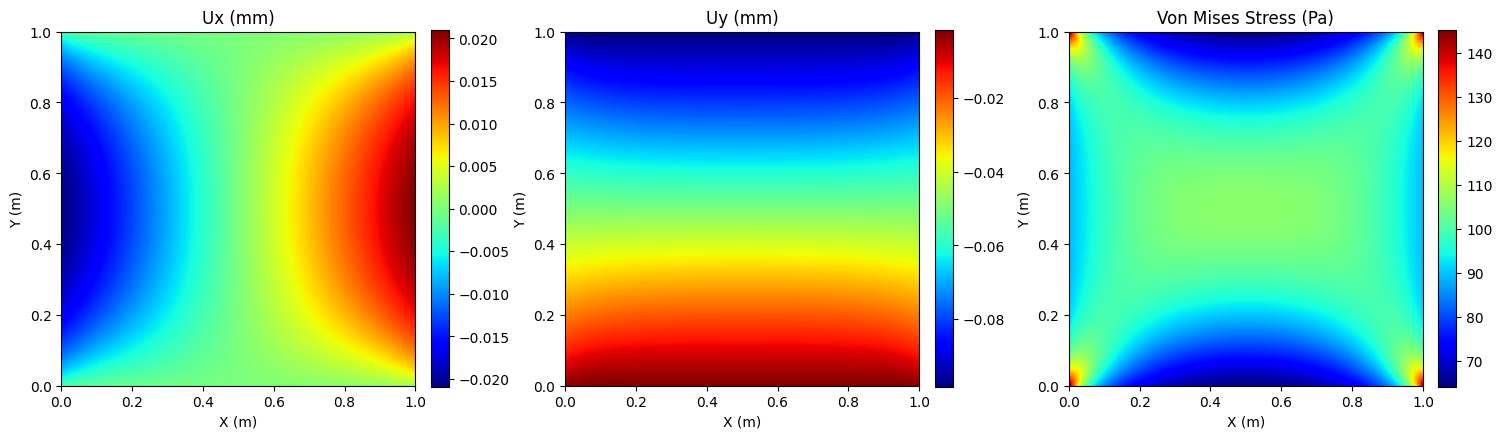

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit, prange
import time

# ==========================================
# 1. 物理参数与网格参数
# ==========================================
L = 1.0              # 正方形边长 (m)
E = 1.0e6            # 杨氏模量 (Pa)
nu = 0.3             # 泊松比
disp_top = -1e-4     # 顶边法向位移 (m)

nu_eff = nu 
G_shear = E / (2.0 * (1.0 + nu))

n_per_side = 200      # 每边单元数 (总数 N = 800)
N = n_per_side * 4

print(f"=== 多核满血版纯 BEM 求解二维弹性受压方板 ===")
print(f"E = {E:.1e} Pa, nu = {nu}, 网格数 N = {N}")

# ==========================================
# 2. 生成常数边界单元网格
# ==========================================
nodes = np.zeros((N, 2))
normals = np.zeros((N, 2))
lengths = np.zeros(N)
edge_ids = np.zeros(N, dtype=int)

dl = L / n_per_side
coords = np.linspace(dl/2, L - dl/2, n_per_side)

idx = 0
for x in coords:
    nodes[idx] = [x, 0]; normals[idx] = [0, -1]; lengths[idx] = dl; edge_ids[idx] = 0; idx += 1
for y in coords:
    nodes[idx] = [L, y]; normals[idx] = [1, 0]; lengths[idx] = dl; edge_ids[idx] = 1; idx += 1
for x in coords[::-1]:
    nodes[idx] = [x, L]; normals[idx] = [0, 1]; lengths[idx] = dl; edge_ids[idx] = 2; idx += 1
for y in coords[::-1]:
    nodes[idx] = [0, y]; normals[idx] = [-1, 0]; lengths[idx] = dl; edge_ids[idx] = 3; idx += 1

# 常数提前计算好，以标量形式传入 Numba，加速极速
C1 = 1.0 / (8.0 * np.pi * G_shear * (1.0 - nu_eff))
C2 = 3.0 - 4.0 * nu_eff
C3 = -1.0 / (4.0 * np.pi * (1.0 - nu_eff))
C4 = 1.0 - 2.0 * nu_eff
gauss_xi, gauss_w = np.polynomial.legendre.leggauss(4)

# ==========================================
# 3. Numba 并行内核：组装 H 和 G 矩阵
# ==========================================
@njit(parallel=True)
def assemble_HG_numba(nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4):
    N = nodes.shape[0]
    H = np.zeros((2*N, 2*N))
    G = np.zeros((2*N, 2*N))
    n_gauss = len(gauss_xi)
    
    # prange 开启多线程并行，所有 CPU 核心将被瞬间拉满！
    for i in prange(N):
        x_source = nodes[i]
        for j in range(N):
            L_j = lengths[j]
            nx = normals[j, 0]; ny = normals[j, 1]
            tx = -ny; ty = nx
            
            r0 = 2*i; r1 = 2*i+1
            c0 = 2*j; c1 = 2*j+1
            
            if i == j:
                H[r0, c0] = 0.5; H[r0, c1] = 0.0
                H[r1, c0] = 0.0; H[r1, c1] = 0.5
                
                g00 = C1 * L_j * (C2 * (1.0 - np.log(L_j/2.0)) + 1.0)
                g11 = C1 * L_j * (C2 * (1.0 - np.log(L_j/2.0)))
                
                # 手工展开矩阵旋转相乘，避开 python 对象的创建开销
                G[r0, c0] = tx * (g00 * tx) + nx * (g11 * nx)
                G[r0, c1] = tx * (g00 * ty) + nx * (g11 * ny)
                G[r1, c0] = ty * (g00 * tx) + ny * (g11 * nx)
                G[r1, c1] = ty * (g00 * ty) + ny * (g11 * ny)
            else:
                y_center = nodes[j]
                H00 = 0.0; H01 = 0.0; H10 = 0.0; H11 = 0.0
                G00 = 0.0; G01 = 0.0; G10 = 0.0; G11 = 0.0
                
                for g in range(n_gauss):
                    y_gpx = y_center[0] + 0.5 * L_j * gauss_xi[g] * tx
                    y_gpy = y_center[1] + 0.5 * L_j * gauss_xi[g] * ty
                    
                    rx = y_gpx - x_source[0]
                    ry = y_gpy - x_source[1]
                    r = np.sqrt(rx*rx + ry*ry)
                    
                    rdx = rx / r; rdy = ry / r
                    dr_dn = rdx * nx + rdy * ny
                    log_1_r = np.log(1.0 / r)
                    
                    hw = 0.5 * L_j * gauss_w[g]
                    
                    # 彻底标量化展开 U_star 和 T_star，剔除一切 numpy 数组创建
                    G00 += C1 * (C2 * log_1_r + rdx*rdx) * hw
                    G01 += C1 * (rdx*rdy) * hw
                    G10 += C1 * (rdx*rdy) * hw
                    G11 += C1 * (C2 * log_1_r + rdy*rdy) * hw
                    
                    H00 += C3/r * (dr_dn*(C4 + 2*rdx*rdx) - C4*(rdx*nx - rdx*nx)) * hw
                    H01 += C3/r * (dr_dn*(2*rdx*rdy) - C4*(rdx*ny - rdy*nx)) * hw
                    H10 += C3/r * (dr_dn*(2*rdy*rdx) - C4*(rdy*nx - rdx*ny)) * hw
                    H11 += C3/r * (dr_dn*(C4 + 2*rdy*rdy) - C4*(rdy*ny - rdy*ny)) * hw
                    
                H[r0, c0] = H00; H[r0, c1] = H01
                H[r1, c0] = H10; H[r1, c1] = H11
                G[r0, c0] = G00; G[r0, c1] = G01
                G[r1, c0] = G10; G[r1, c1] = G11
                
    return H, G

t0 = time.time()
print("正在编译并多核组装矩阵...")
H, G = assemble_HG_numba(nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4)
print(f"H, G 矩阵组装完成，耗时: {time.time()-t0:.3f} s")

# ==========================================
# 4. 施加边界条件与线性求解 (保持不变)
# ==========================================
A = np.zeros((2*N, 2*N))
B = np.zeros(2*N)
u_known = np.zeros(2*N, dtype=bool); u_val = np.zeros(2*N)
t_known = np.zeros(2*N, dtype=bool); t_val = np.zeros(2*N)

for i in range(N):
    eid = edge_ids[i]
    dof_x, dof_y = 2*i, 2*i+1
    
    if eid == 0:   
        u_known[dof_x] = True; u_val[dof_x] = 0.0
        u_known[dof_y] = True; u_val[dof_y] = 0.0
    elif eid == 2: 
        # 注意这里已经修复为了 u_x = 0 (不滑移摩擦边界)
        u_known[dof_x] = True; u_val[dof_x] = 0.0
        u_known[dof_y] = True; u_val[dof_y] = disp_top
    else:          
        t_known[dof_x] = True; t_val[dof_x] = 0.0
        t_known[dof_y] = True; t_val[dof_y] = 0.0

for k in range(2*N):
    if u_known[k]:
        A[:, k] = -G[:, k]
        B -= H[:, k] * u_val[k]
    else:
        A[:, k] = H[:, k]
        B += G[:, k] * t_val[k]

t1 = time.time()
X = np.linalg.solve(A, B)
print(f"线性方程组求逆完成，耗时: {time.time()-t1:.3f} s ")

u_bnd = np.zeros(2*N)
t_bnd = np.zeros(2*N)
for k in range(2*N):
    if u_known[k]:
        u_bnd[k] = u_val[k]; t_bnd[k] = X[k]
    else:
        u_bnd[k] = X[k]; t_bnd[k] = t_val[k]

# ==========================================
# 5. Numba 并行内核：极速计算内部场
# ==========================================
@njit(parallel=True)
def calc_internal_u_numba(pts, nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd):
    N_pts = pts.shape[0]
    N = nodes.shape[0]
    n_gauss = len(gauss_xi)
    u_out = np.zeros((N_pts, 2))
    
    for q in prange(N_pts):
        xi_x = pts[q, 0]; xi_y = pts[q, 1]
        u_x = 0.0; u_y = 0.0
        
        for j in range(N):
            y_center = nodes[j]
            L_j = lengths[j]
            nx = normals[j, 0]; ny = normals[j, 1]
            tx = -ny; ty = nx
            
            U00 = 0.0; U01 = 0.0; U10 = 0.0; U11 = 0.0
            T00 = 0.0; T01 = 0.0; T10 = 0.0; T11 = 0.0
            
            for g in range(n_gauss):
                y_gpx = y_center[0] + 0.5 * L_j * gauss_xi[g] * tx
                y_gpy = y_center[1] + 0.5 * L_j * gauss_xi[g] * ty
                
                rx = y_gpx - xi_x; ry = y_gpy - xi_y
                r = np.sqrt(rx*rx + ry*ry)
                rdx = rx / r; rdy = ry / r
                dr_dn = rdx * nx + rdy * ny
                log_1_r = np.log(1.0 / r)
                hw = 0.5 * L_j * gauss_w[g]
                
                U00 += C1 * (C2 * log_1_r + rdx*rdx) * hw
                U01 += C1 * (rdx*rdy) * hw
                U10 += C1 * (rdx*rdy) * hw
                U11 += C1 * (C2 * log_1_r + rdy*rdy) * hw
                
                T00 += C3/r * (dr_dn*(C4 + 2*rdx*rdx) - C4*(rdx*nx - rdx*nx)) * hw
                T01 += C3/r * (dr_dn*(2*rdx*rdy) - C4*(rdx*ny - rdy*nx)) * hw
                T10 += C3/r * (dr_dn*(2*rdy*rdx) - C4*(rdy*nx - rdx*ny)) * hw
                T11 += C3/r * (dr_dn*(C4 + 2*rdy*rdy) - C4*(rdy*ny - rdy*ny)) * hw
                
            uj_x = u_bnd[2*j]; uj_y = u_bnd[2*j+1]
            tj_x = t_bnd[2*j]; tj_y = t_bnd[2*j+1]
            
            u_x += (U00*tj_x + U01*tj_y) - (T00*uj_x + T01*uj_y)
            u_y += (U10*tj_x + U11*tj_y) - (T10*uj_x + T11*uj_y)
            
        u_out[q, 0] = u_x
        u_out[q, 1] = u_y
        
    return u_out

print("正在多核全速计算域内物理场 (含4倍有限差分)...")
grid_size = 200
coords_1d = np.linspace(0.02, 0.98, grid_size)
XX, YY = np.meshgrid(coords_1d, coords_1d)
internal_pts = np.c_[XX.ravel(), YY.ravel()]

t2 = time.time()
u_int = calc_internal_u_numba(internal_pts, nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)

eps_delta = 1e-4
u_px = calc_internal_u_numba(internal_pts + np.array([eps_delta, 0.0]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)
u_mx = calc_internal_u_numba(internal_pts - np.array([eps_delta, 0.0]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)
u_py = calc_internal_u_numba(internal_pts + np.array([0.0, eps_delta]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)
u_my = calc_internal_u_numba(internal_pts - np.array([0.0, eps_delta]), nodes, normals, lengths, gauss_xi, gauss_w, C1, C2, C3, C4, u_bnd, t_bnd)

du_dx = (u_px - u_mx) / (2*eps_delta)
du_dy = (u_py - u_my) / (2*eps_delta)
print(f"全域位移与偏导数提取完成，耗时: {time.time()-t2:.3f} s ")

# 后处理应变与应力
eps_xx = du_dx[:, 0]
eps_yy = du_dy[:, 1]
eps_xy = 0.5 * (du_dx[:, 1] + du_dy[:, 0])

lam = E * nu / ((1 + nu) * (1 - 2 * nu))
mu_lame = E / (2 * (1 + nu))

sig_xx = lam * (eps_xx + eps_yy) + 2 * mu_lame * eps_xx
sig_yy = lam * (eps_xx + eps_yy) + 2 * mu_lame * eps_yy
sig_xy = 2 * mu_lame * eps_xy

# 【关键修正】：平面应变状态下，Z方向存在约束反力！
sig_zz = nu * (sig_xx + sig_yy)

# 使用完整的三维 Von Mises 公式
von_mises = np.sqrt(0.5 * ((sig_xx - sig_yy)**2 + 
                           (sig_yy - sig_zz)**2 + 
                           (sig_zz - sig_xx)**2) + 
                    3 * sig_xy**2)

# ==========================================
# 6. 绘图与出图
# ==========================================
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(18, 5))

extent = [0, L, 0, L]

# 使用 GridSpec 控制颜色条和子图对齐
gs = gridspec.GridSpec(1, 3, figure=fig, wspace=0.3)

# Ux
ax0 = fig.add_subplot(gs[0, 0])
im0 = ax0.imshow(u_int[:,0].reshape(grid_size, grid_size)*1e3, origin='lower', extent=extent,
                 cmap='jet', aspect='equal')
ax0.set_xlabel('X (m)'); ax0.set_ylabel('Y (m)')
# 色条和子图等高
cbar0 = fig.colorbar(im0, ax=ax0, fraction=0.046, pad=0.04)
ax0.set_title('Ux (mm)')

# Uy
ax1 = fig.add_subplot(gs[0, 1])
im1 = ax1.imshow(u_int[:,1].reshape(grid_size, grid_size)*1e3, origin='lower', extent=extent,
                 cmap='jet', aspect='equal')
ax1.set_xlabel('X (m)'); ax1.set_ylabel('Y (m)')
cbar1 = fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)
ax1.set_title('Uy (mm)')

# Von Mises
ax2 = fig.add_subplot(gs[0, 2])
im2 = ax2.imshow(von_mises.reshape(grid_size, grid_size), origin='lower', extent=extent,
                 cmap='jet', aspect='equal')
ax2.set_xlabel('X (m)'); ax2.set_ylabel('Y (m)')
cbar2 = fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)
ax2.set_title('Von Mises Stress (Pa)')

plt.show()

# 基本解法 MFS 直接求解

这个 notebook 不训练神经网络。未知量是外部源点上基本解的复系数，边界条件直接组成超定线性方程，再用最小二乘一次求解。

源点按真实方板的外部相似正方形布置：比例系数 alpha 控制外部源点正方形边长，alpha = 3 时源点位于以方板中心为中心、边长为 3L 的外方形边界上，且每条边不包含角点。

=== MFS 基本解法参数 ===
L = 1.0, E_real = 1.000e+06 Pa, nu = 0.3, disp_top_real = -1.000e-04 m
归一化: scale_u = 1.000e+04, disp_top* = -1.000e+00, E* = 1.0


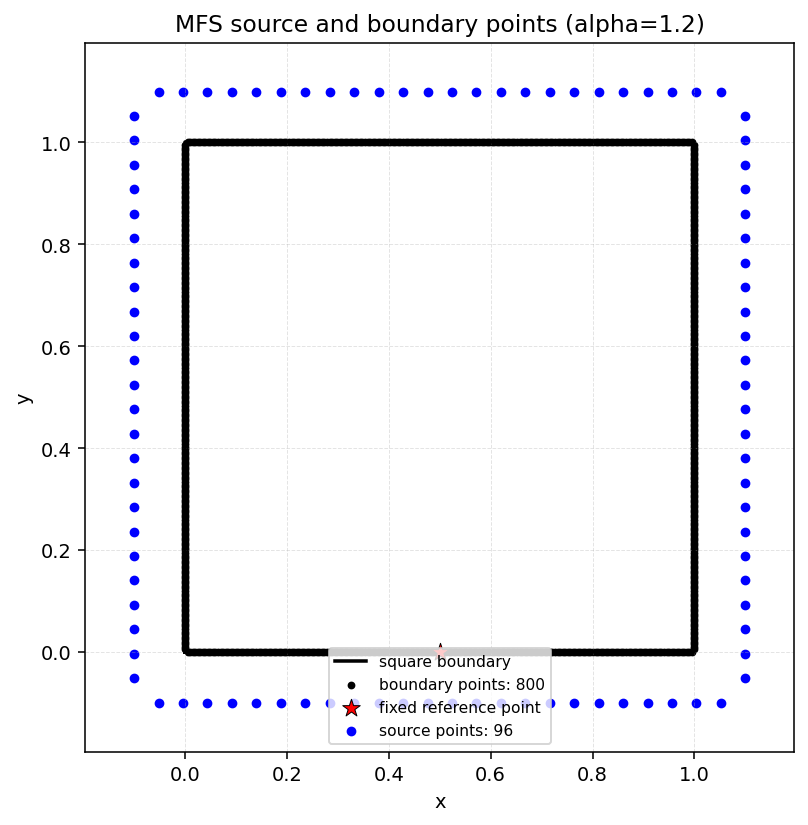

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import time

try:
    import pandas as pd
except ImportError:
    pd = None

try:
    from IPython.display import display
except ImportError:
    display = print

# ==========================================
# 1. 参数与归一化
# ==========================================
# 若前一个 BEM 参考解单元已经运行，这里直接沿用 L、E、nu、disp_top。
L_MFS = float(globals().get("L", 1.0))
E_REAL_MFS = float(globals().get("E", 1.0e6))
NU_MFS = float(globals().get("nu", 0.3))
DISP_TOP_REAL_MFS = float(globals().get("disp_top", -1.0e-4))

# 与前面神经网络 notebook 保持一致：位移放大到顶部位移约为 -1。
SCALE_U_MFS = 1.0 / max(abs(DISP_TOP_REAL_MFS), 1e-15)
E_STAR_MFS = 1.0
DISP_TOP_MFS = DISP_TOP_REAL_MFS * SCALE_U_MFS
G_MFS = E_STAR_MFS / (2.0 * (1.0 + NU_MFS))
KAPPA_MFS = 3.0 - 4.0 * NU_MFS  # 平面应变
STRESS_TO_REAL_MFS = E_REAL_MFS / SCALE_U_MFS

# 默认计算组合
N_SOURCES_PER_SIDE = 24      # 外部源点正方形每条边源点数，不含角点
N_BND_PER_EDGE = 200         # 真实边界每条边配点数，不含角点
SOURCE_SCALE = 1.2           # 外部源点正方形边长比例 alpha

print("=== MFS 基本解法参数 ===")
print(f"L = {L_MFS}, E_real = {E_REAL_MFS:.3e} Pa, nu = {NU_MFS}, disp_top_real = {DISP_TOP_REAL_MFS:.3e} m")
print(f"归一化: scale_u = {SCALE_U_MFS:.3e}, disp_top* = {DISP_TOP_MFS:.3e}, E* = {E_STAR_MFS}")

# ==========================================
# 2. 源点、边界配点生成与可视化
# ==========================================
def build_boundary_points(n_bnd_per_edge=N_BND_PER_EDGE):
    """真实正方形边界配点，不取角点。"""
    t = np.linspace(0.0, L_MFS, int(n_bnd_per_edge) + 2, dtype=float)[1:-1]
    z = np.zeros_like(t)
    o = np.full_like(t, L_MFS)
    return {
        "bottom": np.column_stack([t, z]),
        "right": np.column_stack([o, t]),
        "top": np.column_stack([t[::-1], o]),
        "left": np.column_stack([z, t[::-1]]),
    }

def boundary_points_as_array(boundary_points):
    return np.vstack([boundary_points["bottom"], boundary_points["right"],
                      boundary_points["top"], boundary_points["left"]])

def build_source_points(n_sources_per_side=N_SOURCES_PER_SIDE, source_scale=SOURCE_SCALE):
    """按外部相似正方形布置源点，每条外部边向外平移相同距离，不包含角点。"""
    n = int(n_sources_per_side)
    alpha = float(source_scale)
    if n <= 0:
        raise ValueError("n_sources_per_side 必须为正整数")
    if alpha <= 1.0:
        raise ValueError("source_scale 必须大于 1，源点必须位于真实区域外部")

    center = 0.5 * L_MFS
    half_outer = 0.5 * alpha * L_MFS
    lo = center - half_outer
    hi = center + half_outer

    # 不取角点。alpha=3 且 L=1 时，外部源点正方形为 [-1, 2] x [-1, 2]。
    t = np.linspace(lo, hi, n + 2, dtype=float)[1:-1]
    bottom = np.column_stack([t, np.full_like(t, lo)])
    right = np.column_stack([np.full_like(t, hi), t])
    top = np.column_stack([t[::-1], np.full_like(t, hi)])
    left = np.column_stack([np.full_like(t, lo), t[::-1]])
    return np.vstack([bottom, right, top, left])

def plot_source_boundary_points(n_sources_per_side=N_SOURCES_PER_SIDE,
                                n_bnd_per_edge=N_BND_PER_EDGE,
                                source_scale=SOURCE_SCALE,
                                ax=None):
    src = build_source_points(n_sources_per_side, source_scale)
    bnd = build_boundary_points(n_bnd_per_edge)
    bnd_all = boundary_points_as_array(bnd)

    if ax is None:
        fig, ax = plt.subplots(figsize=(6.2, 6.0), dpi=140)
    else:
        fig = ax.figure

    square = np.array([[0, 0], [L_MFS, 0], [L_MFS, L_MFS], [0, L_MFS], [0, 0]], dtype=float)
    ax.plot(square[:, 0], square[:, 1], color="black", lw=1.8, label="square boundary")
    ax.scatter(bnd_all[:, 0], bnd_all[:, 1], s=9, c="black", label=f"boundary points: {len(bnd_all)}")
    ax.scatter([0.5 * L_MFS], [0.0], marker="*", s=90, c="red", edgecolors="black",
               linewidths=0.5, label="fixed reference point", zorder=4)
    ax.scatter(src[:, 0], src[:, 1], s=16, c="blue", label=f"source points: {len(src)}")

    margin = 0.08 * max(L_MFS, np.ptp(src[:, 0]), np.ptp(src[:, 1]))
    ax.set_xlim(src[:, 0].min() - margin, src[:, 0].max() + margin)
    ax.set_ylim(src[:, 1].min() - margin, src[:, 1].max() + margin)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(f"MFS source and boundary points (alpha={source_scale:g})")
    ax.grid(True, ls="--", lw=0.5, alpha=0.35)
    ax.legend(loc="lower center", frameon=True, fontsize=8)
    plt.tight_layout()
    return fig, ax, src, bnd

# 先画默认源点/边界点分布，确认源点是外部相似正方形，不是圆角外扩。
plot_source_boundary_points();


In [6]:
# ==========================================
# 3. MFS 复势基本解与直接最小二乘求解
# ==========================================
def _as_complex(points):
    points = np.asarray(points, dtype=float)
    return points[:, 0] + 1j * points[:, 1]

def coefficient_count(n_basis):
    # phi 源点复系数 + psi 源点复系数 + phi/psi 的复常数和复一次项
    return 4 * int(n_basis) + 8

def unpack_coeffs(coeffs, n_basis):
    coeffs = np.asarray(coeffs, dtype=float)
    n = int(n_basis)
    idx = 0
    w_phi = coeffs[idx:idx+n] + 1j * coeffs[idx+n:idx+2*n]
    idx += 2 * n
    w_psi = coeffs[idx:idx+n] + 1j * coeffs[idx+n:idx+2*n]
    idx += 2 * n
    phi0 = coeffs[idx] + 1j * coeffs[idx+1]
    idx += 2
    phi1 = coeffs[idx] + 1j * coeffs[idx+1]
    idx += 2
    psi0 = coeffs[idx] + 1j * coeffs[idx+1]
    idx += 2
    psi1 = coeffs[idx] + 1j * coeffs[idx+1]
    return w_phi, w_psi, phi0, phi1, psi0, psi1

def prepare_mfs_cache(points, source_points):
    """预计算 Log(z-zeta)、1/(z-zeta)、-1/(z-zeta)^2。"""
    z = _as_complex(points)
    src = _as_complex(source_points)
    dz = z[:, None] - src[None, :]

    # 每个源点的对数支路朝向方板中心，减少内部区域内的相位跳变。
    center = 0.5 * L_MFS + 0.5j * L_MFS
    branch_angle = np.angle(center - src)
    rotated = dz * np.exp(-1j * branch_angle[None, :])

    basis = np.log(np.abs(rotated)) + 1j * np.angle(rotated)
    d1 = 1.0 / dz
    d2 = -1.0 / (dz * dz)
    return {
        "z": z,
        "basis": basis,
        "d1": d1,
        "d2": d2,
        "n_basis": len(src),
    }

def fields_from_coeffs(coeffs, source_points=None, points=None, cache=None):
    """由 MFS 系数计算 ux, uy, sig_xx, sig_yy, sig_xy。输出为归一化量。"""
    if cache is None:
        if source_points is None or points is None:
            raise ValueError("必须传入 cache，或同时传入 source_points 和 points")
        cache = prepare_mfs_cache(points, source_points)

    z = cache["z"]
    basis = cache["basis"]
    d1 = cache["d1"]
    d2 = cache["d2"]
    n_basis = cache["n_basis"]

    w_phi, w_psi, phi0, phi1, psi0, psi1 = unpack_coeffs(coeffs, n_basis)

    phi = basis @ w_phi + phi0 + phi1 * z
    psi = basis @ w_psi + psi0 + psi1 * z
    dphi = d1 @ w_phi + phi1
    d2phi = d2 @ w_phi
    dpsi = d1 @ w_psi + psi1

    disp_complex = (KAPPA_MFS * phi - z * np.conj(dphi) - np.conj(psi)) / (2.0 * G_MFS)
    ux = disp_complex.real
    uy = disp_complex.imag

    sum_sig = 4.0 * dphi.real
    diff = 2.0 * (np.conj(z) * d2phi + dpsi)
    sig_xx = 0.5 * (sum_sig - diff.real)
    sig_yy = 0.5 * (sum_sig + diff.real)
    sig_xy = 0.5 * diff.imag
    return ux, uy, sig_xx, sig_yy, sig_xy

def make_boundary_caches(boundary_points, source_points):
    return {name: prepare_mfs_cache(pts, source_points) for name, pts in boundary_points.items()}

def boundary_residual(coeffs, boundary_caches):
    """边界残差：底边固支位移、顶边给定位移、左右边自由面力。"""
    ux_b, uy_b, _, _, _ = fields_from_coeffs(coeffs, cache=boundary_caches["bottom"])
    ux_t, uy_t, _, _, _ = fields_from_coeffs(coeffs, cache=boundary_caches["top"])
    _, _, sig_xx_l, _, sig_xy_l = fields_from_coeffs(coeffs, cache=boundary_caches["left"])
    _, _, sig_xx_r, _, sig_xy_r = fields_from_coeffs(coeffs, cache=boundary_caches["right"])

    return np.concatenate([
        ux_b,
        uy_b,
        ux_t,
        uy_t - DISP_TOP_MFS,
        sig_xx_l,
        sig_xy_l,
        sig_xx_r,
        sig_xy_r,
    ])

def solve_mfs(n_sources_per_side=N_SOURCES_PER_SIDE,
              n_bnd_per_edge=N_BND_PER_EDGE,
              source_scale=SOURCE_SCALE,
              rcond=None,
              progress=True):
    """直接组装边界方程 A c = b，并用最小二乘求 MFS 系数。"""
    t0 = time.time()
    source_points = build_source_points(n_sources_per_side, source_scale)
    boundary_points = build_boundary_points(n_bnd_per_edge)
    boundary_caches = make_boundary_caches(boundary_points, source_points)

    n_unknown = coefficient_count(len(source_points))
    zero = np.zeros(n_unknown, dtype=float)
    r0 = boundary_residual(zero, boundary_caches)
    A = np.empty((r0.size, n_unknown), dtype=float)

    if progress:
        print(f"组装 MFS 线性系统: rows={r0.size}, unknowns={n_unknown}")

    for k in range(n_unknown):
        e = np.zeros(n_unknown, dtype=float)
        e[k] = 1.0
        A[:, k] = boundary_residual(e, boundary_caches) - r0

    coeffs, residuals, rank, singular_values = np.linalg.lstsq(A, -r0, rcond=rcond)
    final_residual = boundary_residual(coeffs, boundary_caches)
    elapsed = time.time() - t0

    rms = float(np.sqrt(np.mean(final_residual**2)))
    max_abs = float(np.max(np.abs(final_residual)))
    cond_est = float(singular_values[0] / singular_values[-1]) if singular_values.size and singular_values[-1] > 0 else np.inf

    summary = {
        "source_per_side": int(n_sources_per_side),
        "source_total": int(len(source_points)),
        "boundary_per_edge": int(n_bnd_per_edge),
        "boundary_total": int(4 * n_bnd_per_edge),
        "unknowns": int(n_unknown),
        "rank": int(rank),
        "boundary_rms": rms,
        "boundary_max_abs": max_abs,
        "condition_est": cond_est,
        "solve_time_s": float(elapsed),
    }

    return {
        "coeffs": coeffs,
        "source_points": source_points,
        "boundary_points": boundary_points,
        "summary": summary,
        "boundary_residual": final_residual,
        "singular_values": singular_values,
    }

def print_mfs_table(rows):
    cols = [
        "source_per_side", "source_total", "boundary_per_edge", "boundary_total",
        "unknowns", "rank", "boundary_rms", "boundary_max_abs",
        "L2_ux", "L2_uy", "L2_mean", "solve_time_s",
    ]
    rows2 = [{k: row.get(k, np.nan) for k in cols} for row in rows]
    if pd is not None:
        display(pd.DataFrame(rows2))
        return

    header = (
        f"{'src/side':>8} {'src total':>9} {'bnd/edge':>9} {'bnd total':>9} "
        f"{'unknowns':>8} {'rank':>6} {'bnd rms':>12} {'bnd max':>12} "
        f"{'L2 ux':>12} {'L2 uy':>12} {'L2 mean':>12} {'time(s)':>9}"
    )
    print(header)
    print("-" * len(header))
    for row in rows2:
        print(
            f"{int(row['source_per_side']):8d} {int(row['source_total']):9d} "
            f"{int(row['boundary_per_edge']):9d} {int(row['boundary_total']):9d} "
            f"{int(row['unknowns']):8d} {int(row['rank']):6d} "
            f"{row['boundary_rms']:12.4e} {row['boundary_max_abs']:12.4e} "
            f"{row['L2_ux']:12.4e} {row['L2_uy']:12.4e} {row['L2_mean']:12.4e} "
            f"{row['solve_time_s']:9.2f}"
        )


组装 MFS 线性系统: rows=1600, unknowns=392

=== MFS 误差结果 ===


,source_per_side,source_total,boundary_per_edge,boundary_total,unknowns,rank,boundary_rms,boundary_max_abs,L2_ux,L2_uy,L2_mean,solve_time_s
0,24,96,200,800,392,390,0.000221,0.002687,0.001066,0.00011,0.000588,0.532341


MFS 预测云图已保存: mfs_prediction_clouds\mfs_prediction_6_clouds.png
  mfs_prediction_clouds\mfs_prediction_ux.png
  mfs_prediction_clouds\mfs_prediction_uy.png
  mfs_prediction_clouds\mfs_prediction_sxx.png
  mfs_prediction_clouds\mfs_prediction_syy.png
  mfs_prediction_clouds\mfs_prediction_sxy.png
  mfs_prediction_clouds\mfs_prediction_von_mises.png


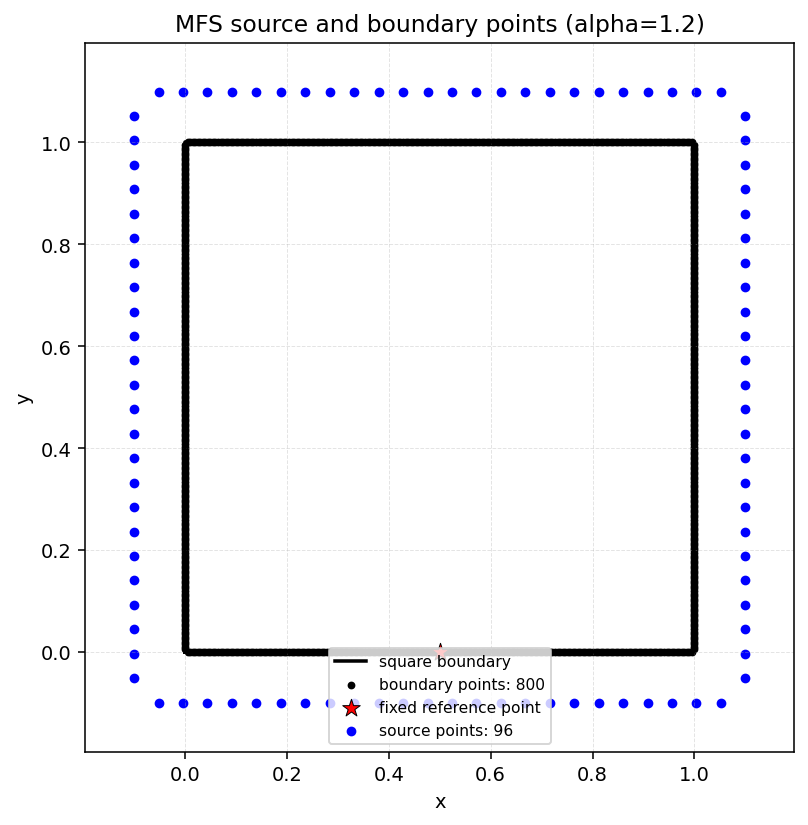

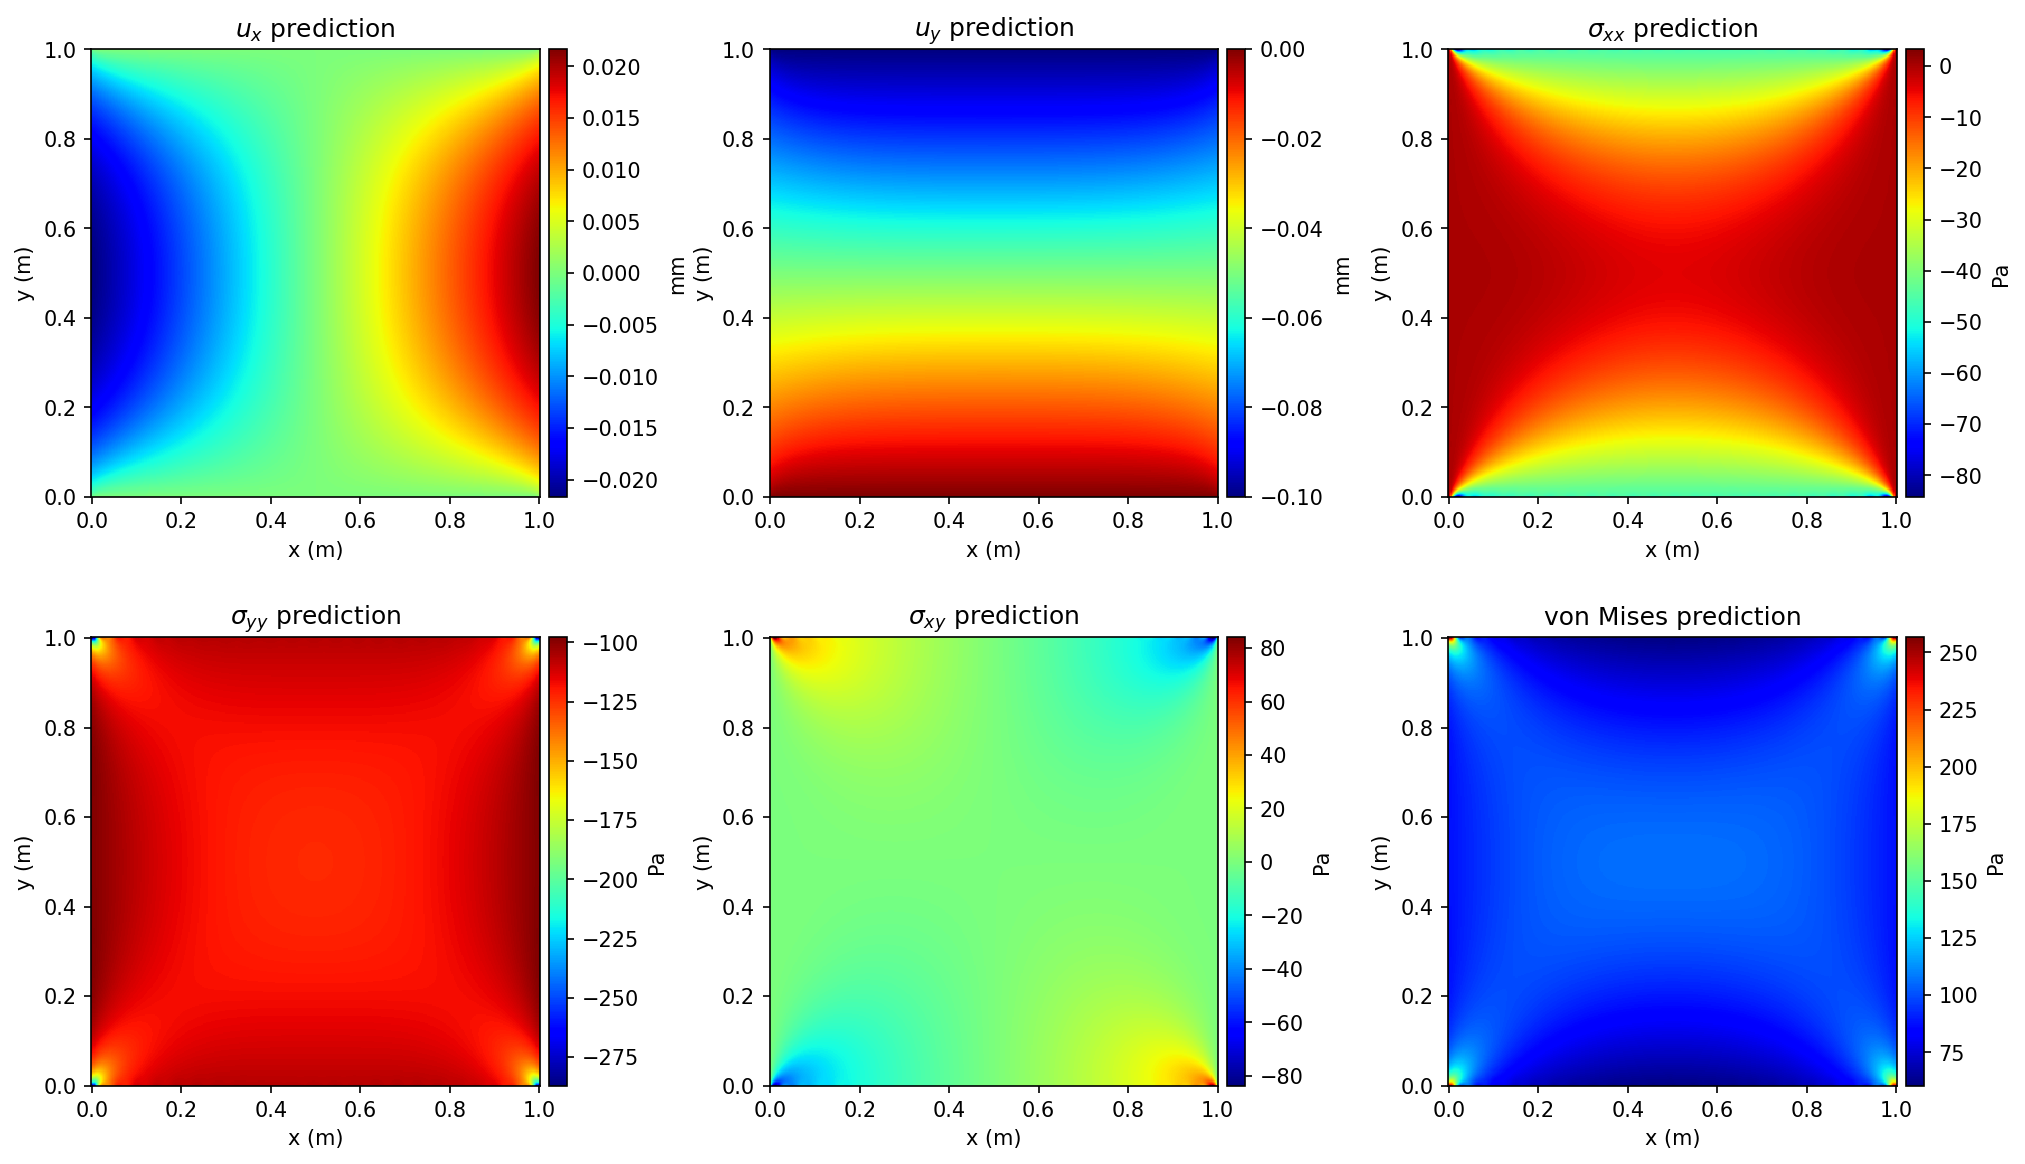

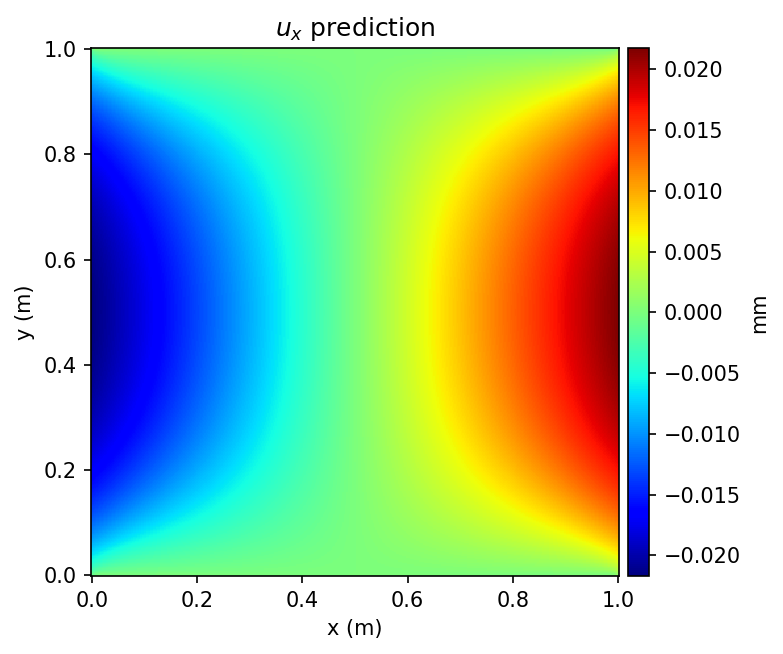

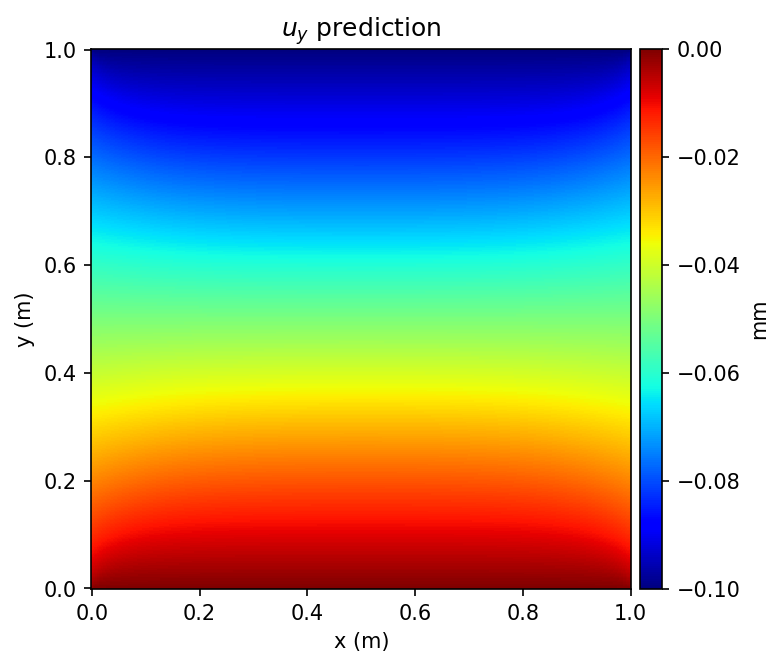

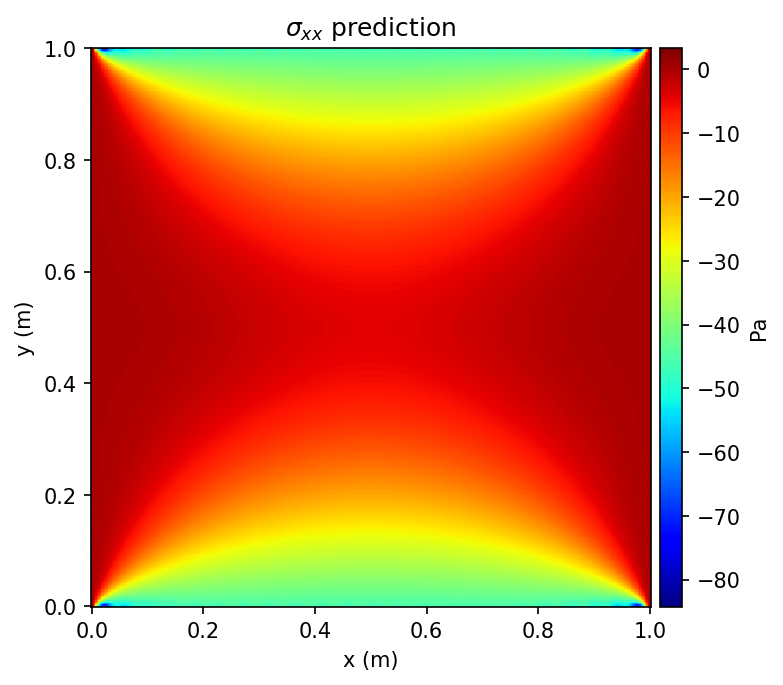

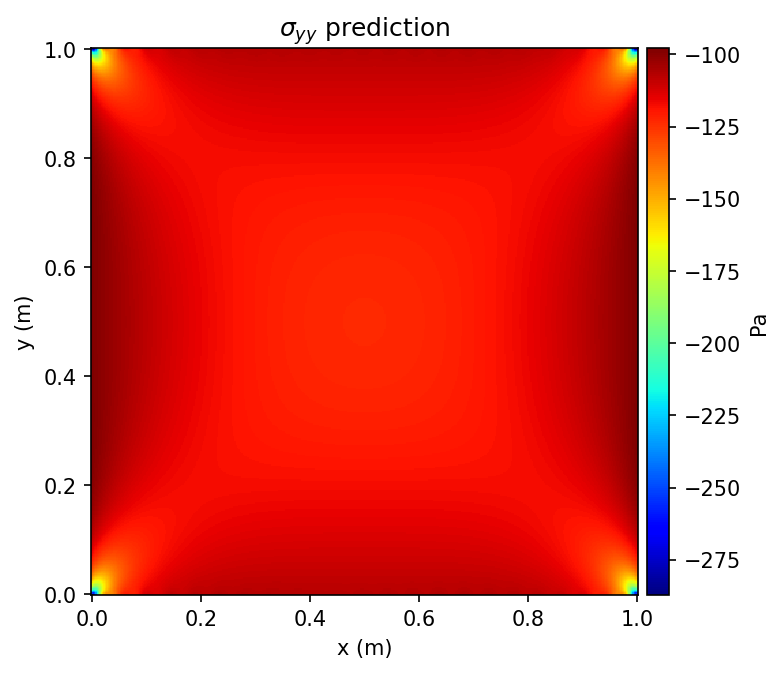

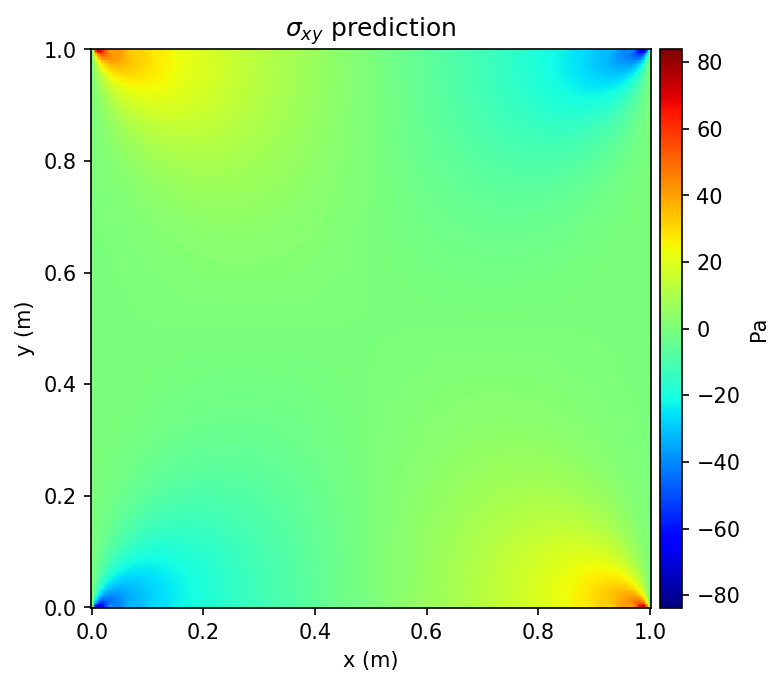

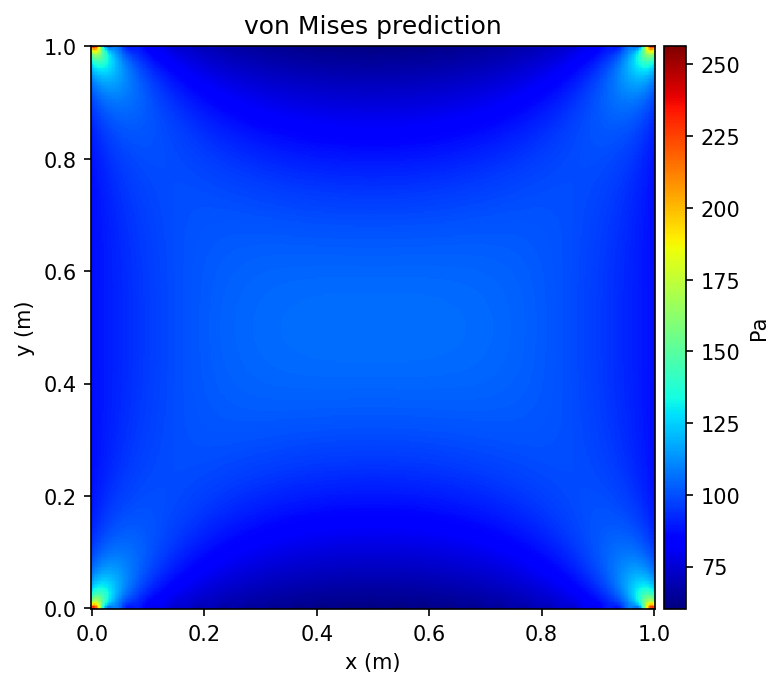

C:\Users\magic\AppData\Local\Temp\ipykernel_53560\2268889269.py:236: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


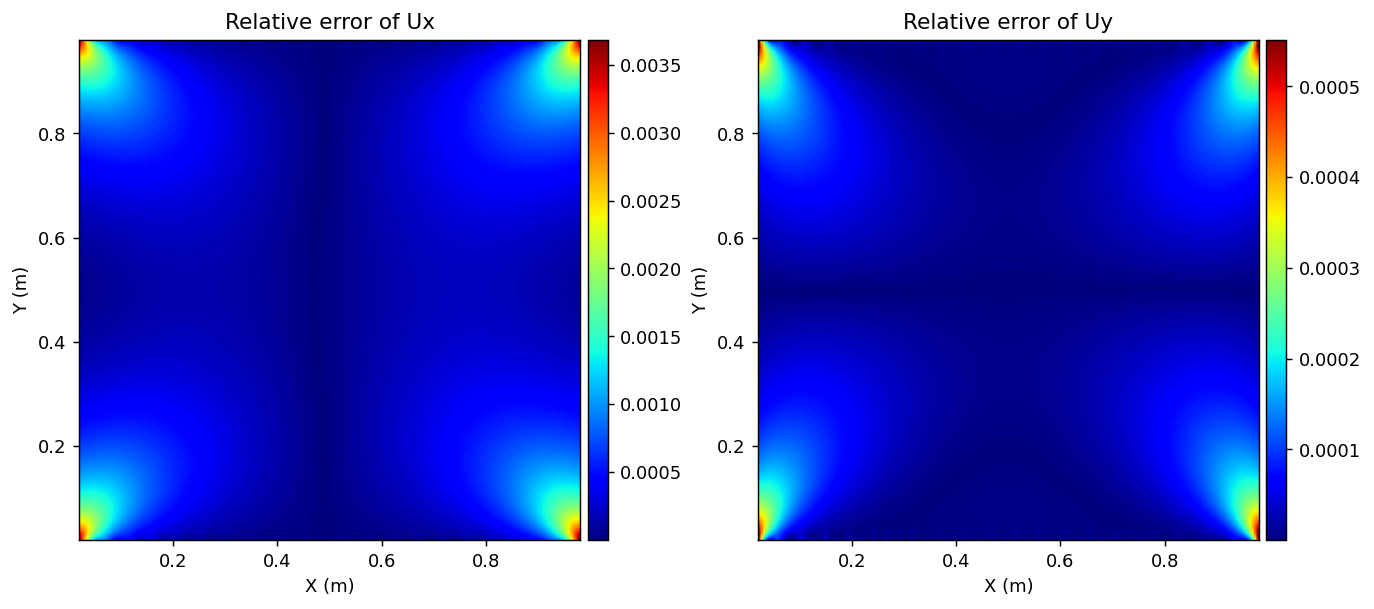

In [7]:
# ==========================================
# 4. 与 BEM 参考解比较、MFS 预测云图和误差图
# ==========================================
def _infer_grid(points):
    n = int(round(np.sqrt(len(points))))
    if n * n != len(points):
        return None
    xs = np.unique(np.round(points[:, 0], 12))
    ys = np.unique(np.round(points[:, 1], 12))
    if len(xs) == n and len(ys) == n:
        return n
    return None

def _values_to_regular_grid(points, values, decimals=12):
    """把规则网格散点值整理成 pcolormesh 可用的二维矩阵。"""
    points = np.asarray(points, dtype=float)
    values = np.asarray(values, dtype=float).reshape(-1)
    xr = np.round(points[:, 0], decimals)
    yr = np.round(points[:, 1], decimals)
    xs = np.unique(xr)
    ys = np.unique(yr)
    if xs.size * ys.size != values.size:
        raise ValueError("当前点集不是规则网格，无法直接绘制规则云图。")

    grid = np.full((ys.size, xs.size), np.nan, dtype=float)
    ix = np.searchsorted(xs, xr)
    iy = np.searchsorted(ys, yr)
    grid[iy, ix] = values
    if np.isnan(grid).any():
        raise ValueError("规则网格存在缺失点，请检查 eval_points。")
    return xs, ys, grid

def _add_equal_height_colorbar(fig, ax, im, label):
    """让 colorbar 与云图坐标轴等高。"""
    from mpl_toolkits.axes_grid1 import make_axes_locatable

    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="4%", pad=0.06)
    cbar = fig.colorbar(im, cax=cax)
    cbar.set_label(label)
    return cbar

def make_regular_mfs_grid(n_grid=401):
    """生成 MFS 预测云图用的规则网格。"""
    xs = np.linspace(0.0, L_MFS, int(n_grid), dtype=float)
    ys = np.linspace(0.0, L_MFS, int(n_grid), dtype=float)
    XX, YY = np.meshgrid(xs, ys, indexing="xy")
    pts = np.column_stack([XX.ravel(), YY.ravel()])
    return xs, ys, XX, YY, pts

def predict_mfs_physical_fields(solution, eval_points, batch_size=20000):
    """预测 MFS 的六个物理量，并转换为真实量纲。"""
    eval_points = np.asarray(eval_points, dtype=float)
    source_points = solution["source_points"]
    coeffs = solution["coeffs"]

    ux_chunks, uy_chunks = [], []
    sxx_chunks, syy_chunks, sxy_chunks = [], [], []

    for start in range(0, len(eval_points), int(batch_size)):
        end = min(start + int(batch_size), len(eval_points))
        pts_batch = eval_points[start:end]
        cache = prepare_mfs_cache(pts_batch, source_points)
        ux, uy, sig_xx, sig_yy, sig_xy = fields_from_coeffs(coeffs, cache=cache)

        ux_chunks.append(ux / SCALE_U_MFS)
        uy_chunks.append(uy / SCALE_U_MFS)
        sxx_chunks.append(sig_xx * STRESS_TO_REAL_MFS)
        syy_chunks.append(sig_yy * STRESS_TO_REAL_MFS)
        sxy_chunks.append(sig_xy * STRESS_TO_REAL_MFS)

    ux_real = np.concatenate(ux_chunks)
    uy_real = np.concatenate(uy_chunks)
    sig_xx_real = np.concatenate(sxx_chunks)
    sig_yy_real = np.concatenate(syy_chunks)
    sig_xy_real = np.concatenate(sxy_chunks)

    # 平面应变：sigma_zz = nu * (sigma_xx + sigma_yy)
    sig_zz_real = NU_MFS * (sig_xx_real + sig_yy_real)
    von_mises_real = np.sqrt(
        0.5 * ((sig_xx_real - sig_yy_real)**2 +
               (sig_yy_real - sig_zz_real)**2 +
               (sig_zz_real - sig_xx_real)**2) +
        3.0 * sig_xy_real**2
    )

    return {
        "ux_real": ux_real,
        "uy_real": uy_real,
        "sig_xx_real": sig_xx_real,
        "sig_yy_real": sig_yy_real,
        "sig_xy_real": sig_xy_real,
        "von_mises_real": von_mises_real,
    }

def evaluate_mfs_error(solution, eval_points=None, ref_u=None, batch_size=20000):
    if eval_points is None:
        if "internal_pts" not in globals():
            raise RuntimeError("请先运行 BEM 参考解单元，确保 internal_pts 已经存在。")
        eval_points = globals()["internal_pts"]
    if ref_u is None:
        if "u_int" not in globals():
            raise RuntimeError("请先运行 BEM 参考解单元，确保 u_int 已经存在。")
        ref_u = globals()["u_int"]

    fields = predict_mfs_physical_fields(solution, eval_points, batch_size=batch_size)

    u_ref = np.asarray(ref_u)[:, 0]
    v_ref = np.asarray(ref_u)[:, 1]
    l2_ux = np.linalg.norm(fields["ux_real"] - u_ref, 2) / max(np.linalg.norm(u_ref, 2), 1e-15)
    l2_uy = np.linalg.norm(fields["uy_real"] - v_ref, 2) / max(np.linalg.norm(v_ref, 2), 1e-15)

    metrics = {
        "L2_ux": float(l2_ux),
        "L2_uy": float(l2_uy),
        "L2_mean": float(0.5 * (l2_ux + l2_uy)),
        "L2_max": float(max(l2_ux, l2_uy)),
    }
    return metrics, fields

def plot_mfs_prediction_clouds(
    solution,
    eval_points=None,
    fields=None,
    grid_n=401,
    batch_size=20000,
    out_dir="mfs_prediction_clouds",
    save_fig=True,
    show=True,
):
    """绘制 MFS 的 ux, uy, sigma_xx, sigma_yy, sigma_xy, von Mises 六张预测云图。"""
    from pathlib import Path

    if eval_points is None:
        _, _, _, _, eval_points = make_regular_mfs_grid(grid_n)

    if fields is None or len(np.asarray(fields.get("ux_real", []))) != len(eval_points):
        fields = predict_mfs_physical_fields(solution, eval_points, batch_size=batch_size)

    plot_items = [
        ("ux", fields["ux_real"] * 1e3, r"$u_x$ prediction", "mm"),
        ("uy", fields["uy_real"] * 1e3, r"$u_y$ prediction", "mm"),
        ("sxx", fields["sig_xx_real"], r"$\sigma_{xx}$ prediction", "Pa"),
        ("syy", fields["sig_yy_real"], r"$\sigma_{yy}$ prediction", "Pa"),
        ("sxy", fields["sig_xy_real"], r"$\sigma_{xy}$ prediction", "Pa"),
        ("von_mises", fields["von_mises_real"], "von Mises prediction", "Pa"),
    ]

    fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.0), dpi=150)
    for ax, (_, values, title, unit) in zip(axes.ravel(), plot_items):
        xs, ys, grid_values = _values_to_regular_grid(eval_points, values)
        im = ax.pcolormesh(xs, ys, grid_values, shading="auto", cmap="jet")
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlabel("x (m)")
        ax.set_ylabel("y (m)")
        ax.set_title(title)
        _add_equal_height_colorbar(fig, ax, im, unit)

    fig.tight_layout()

    single_paths = []
    if save_fig:
        out_path = Path(out_dir)
        out_path.mkdir(parents=True, exist_ok=True)
        combined_path = out_path / "mfs_prediction_6_clouds.png"
        fig.savefig(combined_path, dpi=300, bbox_inches="tight")

        for name, values, title, unit in plot_items:
            single_fig, single_ax = plt.subplots(figsize=(5.2, 4.8), dpi=150)
            xs, ys, grid_values = _values_to_regular_grid(eval_points, values)
            im = single_ax.pcolormesh(xs, ys, grid_values, shading="auto", cmap="jet")
            single_ax.set_aspect("equal", adjustable="box")
            single_ax.set_xlabel("x (m)")
            single_ax.set_ylabel("y (m)")
            single_ax.set_title(title)
            _add_equal_height_colorbar(single_fig, single_ax, im, unit)
            single_fig.tight_layout()

            save_path = out_path / f"mfs_prediction_{name}.png"
            single_fig.savefig(save_path, dpi=300, bbox_inches="tight")
            single_paths.append(save_path)
            if not show:
                plt.close(single_fig)

        print(f"MFS 预测云图已保存: {combined_path}")
        for save_path in single_paths:
            print(f"  {save_path}")

    if show:
        plt.show()
    else:
        plt.close(fig)

    fields["points"] = np.asarray(eval_points)
    return fields, fig

# 兼容旧函数名：现在 plot_mfs_clouds 也输出六个物理量。
def plot_mfs_clouds(solution, eval_points=None, fields=None, **kwargs):
    return plot_mfs_prediction_clouds(solution, eval_points=eval_points, fields=fields, **kwargs)

def plot_mfs_error_clouds(solution, eval_points=None, ref_u=None, fields=None):
    if eval_points is None:
        eval_points = globals()["internal_pts"]
    if ref_u is None:
        ref_u = globals()["u_int"]
    if fields is None or len(np.asarray(fields.get("ux_real", []))) != len(eval_points):
        _, fields = evaluate_mfs_error(solution, eval_points=eval_points, ref_u=ref_u)

    grid_n = _infer_grid(eval_points)
    if grid_n is None:
        raise ValueError("当前 eval_points 不是规则网格，无法用 imshow 画误差云图。")

    ref_u = np.asarray(ref_u)
    err_ux = np.abs(fields["ux_real"] - ref_u[:, 0])
    err_uy = np.abs(fields["uy_real"] - ref_u[:, 1])
    rel_ux = err_ux / max(np.max(np.abs(ref_u[:, 0])), 1e-15)
    rel_uy = err_uy / max(np.max(np.abs(ref_u[:, 1])), 1e-15)

    extent = [eval_points[:, 0].min(), eval_points[:, 0].max(),
              eval_points[:, 1].min(), eval_points[:, 1].max()]

    fig = plt.figure(figsize=(12, 5), dpi=130)
    gs = gridspec.GridSpec(1, 2, figure=fig, wspace=0.28)
    for i, (values, title) in enumerate([
        (rel_ux, "Relative error of Ux"),
        (rel_uy, "Relative error of Uy"),
    ]):
        ax = fig.add_subplot(gs[0, i])
        im = ax.imshow(values.reshape(grid_n, grid_n), origin="lower",
                       extent=extent, cmap="jet", aspect="equal")
        ax.set_xlabel("X (m)")
        ax.set_ylabel("Y (m)")
        ax.set_title(title)
        _add_equal_height_colorbar(fig, ax, im, "")

    plt.tight_layout()
    return fig

def run_mfs_case(n_sources_per_side=N_SOURCES_PER_SIDE,
                 n_bnd_per_edge=N_BND_PER_EDGE,
                 source_scale=SOURCE_SCALE,
                 make_plots=True):
    solution = solve_mfs(n_sources_per_side, n_bnd_per_edge, source_scale)
    metrics, fields = evaluate_mfs_error(solution)
    solution["metrics"] = metrics
    solution["fields"] = fields
    row = {**solution["summary"], **metrics}

    print("\n=== MFS 误差结果 ===")
    print_mfs_table([row])

    if make_plots:
        plot_source_boundary_points(n_sources_per_side, n_bnd_per_edge, source_scale)
        prediction_fields, prediction_fig = plot_mfs_prediction_clouds(
            solution,
            grid_n=MFS_PRED_GRID_N,
            batch_size=MFS_PRED_BATCH_SIZE,
            out_dir=MFS_PRED_OUT_DIR,
            save_fig=True,
            show=True,
        )
        solution["prediction_fields"] = prediction_fields
        solution["prediction_fig"] = prediction_fig
        plot_mfs_error_clouds(solution, fields=fields)

    return solution

def run_mfs_sweep(source_counts_per_side, boundary_counts_per_edge,
                  source_scale=SOURCE_SCALE, make_heatmap=True):
    rows = []
    best_solution = None
    best_row = None
    total = len(source_counts_per_side) * len(boundary_counts_per_edge)
    case_id = 0

    for n_src in source_counts_per_side:
        for n_bnd in boundary_counts_per_edge:
            case_id += 1
            print(f"\n[{case_id}/{total}] source_per_side={n_src}, boundary_per_edge={n_bnd}")
            sol = solve_mfs(n_src, n_bnd, source_scale)
            metrics, fields = evaluate_mfs_error(sol)
            sol["metrics"] = metrics
            sol["fields"] = fields
            row = {**sol["summary"], **metrics}
            rows.append(row)

            if best_row is None or row["L2_mean"] < best_row["L2_mean"]:
                best_solution = sol
                best_row = row

    print("\n=== MFS 参数扫描结果 ===")
    print_mfs_table(rows)

    if make_heatmap and len(rows) > 1:
        plot_mfs_sweep_heatmaps(rows)

    return rows, best_solution, best_row

def plot_mfs_sweep_heatmaps(rows, metric_names=("L2_ux", "L2_uy", "L2_mean")):
    source_totals = sorted({row["source_total"] for row in rows})
    boundary_totals = sorted({row["boundary_total"] for row in rows})
    fig, axes = plt.subplots(1, len(metric_names), figsize=(5.2 * len(metric_names), 4.2), dpi=130)
    if len(metric_names) == 1:
        axes = [axes]

    for ax, metric in zip(axes, metric_names):
        mat = np.full((len(source_totals), len(boundary_totals)), np.nan)
        for row in rows:
            i = source_totals.index(row["source_total"])
            j = boundary_totals.index(row["boundary_total"])
            mat[i, j] = row[metric]

        im = ax.imshow(mat, origin="lower", cmap="viridis", aspect="auto")
        ax.set_xticks(np.arange(len(boundary_totals)))
        ax.set_xticklabels(boundary_totals)
        ax.set_yticks(np.arange(len(source_totals)))
        ax.set_yticklabels(source_totals)
        ax.set_xlabel("total boundary collocation points")
        ax.set_ylabel("total source points")
        ax.set_title(metric)
        for i in range(mat.shape[0]):
            for j in range(mat.shape[1]):
                if np.isfinite(mat[i, j]):
                    ax.text(j, i, f"{mat[i, j]:.1e}", ha="center", va="center",
                            color="white", fontsize=8)
        _add_equal_height_colorbar(fig, ax, im, metric)
    plt.tight_layout()
    return fig, axes

# ==========================================
# 5. 运行
# ==========================================
RUN_SINGLE_CASE = True
RUN_SWEEP = False

# MFS 预测云图设置：401x401 与 COMSOL 参考解导出分辨率一致。
MFS_PRED_GRID_N = 401
MFS_PRED_BATCH_SIZE = 20000
MFS_PRED_OUT_DIR = "mfs_prediction_clouds"

if RUN_SINGLE_CASE:
    mfs_solution = run_mfs_case(
        n_sources_per_side=N_SOURCES_PER_SIDE,
        n_bnd_per_edge=N_BND_PER_EDGE,
        source_scale=SOURCE_SCALE,
        make_plots=True,
    )

if RUN_SWEEP:
    SWEEP_SOURCE_COUNTS_PER_SIDE = [12, 24, 36]
    SWEEP_BOUNDARY_COUNTS_PER_EDGE = [100, 200]
    mfs_sweep_rows, mfs_best_solution, mfs_best_row = run_mfs_sweep(
        SWEEP_SOURCE_COUNTS_PER_SIDE,
        SWEEP_BOUNDARY_COUNTS_PER_EDGE,
        source_scale=SOURCE_SCALE,
        make_heatmap=True,
    )


## MFS 相对于 COMSOL 参考解的六物理量误差分析

读取 COMSOL plane strain 参考解，计算 MFS 的六物理量相对 L2 误差，并绘制绝对误差云图和归一化误差云图。

计算 MFS 相对于 COMSOL 参考解的六物理量 L2 误差、绝对误差云图和归一化误差云图...
--------------------------------------------------------------------------------------------
MFS vs COMSOL six-field errors
--------------------------------------------------------------------------------------------
       Field      Relative L2      Max abs error     Max norm error
--------------------------------------------------------------------------------------------
          ux       1.4741e-03         6.1934e-07         2.8587e-02
          uy       1.9595e-04         5.8690e-07         5.8748e-03
         sxx       4.8609e-02         1.1383e+02         9.9135e-01
         syy       6.6396e-03         1.1898e+02         3.0924e-01
         sxy       6.5550e-02         7.0087e+01         8.0893e-01
   von_mises       9.2082e-03         9.3217e+01         2.8286e-01
--------------------------------------------------------------------------------------------


,field,relative_L2,max_abs_error,max_normalized_error
0,ux,0.001474,6.193430e-07,0.028587
1,uy,0.000196,5.869004e-07,0.005875
2,sxx,0.048609,1.138282e+02,0.991354
3,syy,0.006640,1.189800e+02,0.309238
4,sxy,0.065550,7.008690e+01,0.808933
5,von_mises,0.009208,9.321694e+01,0.282862


误差云图已保存: mfs_comsol_error_clouds\mfs_comsol_absolute_error_6_fields.png
误差云图已保存: mfs_comsol_error_clouds\mfs_comsol_normalized_error_6_fields.png


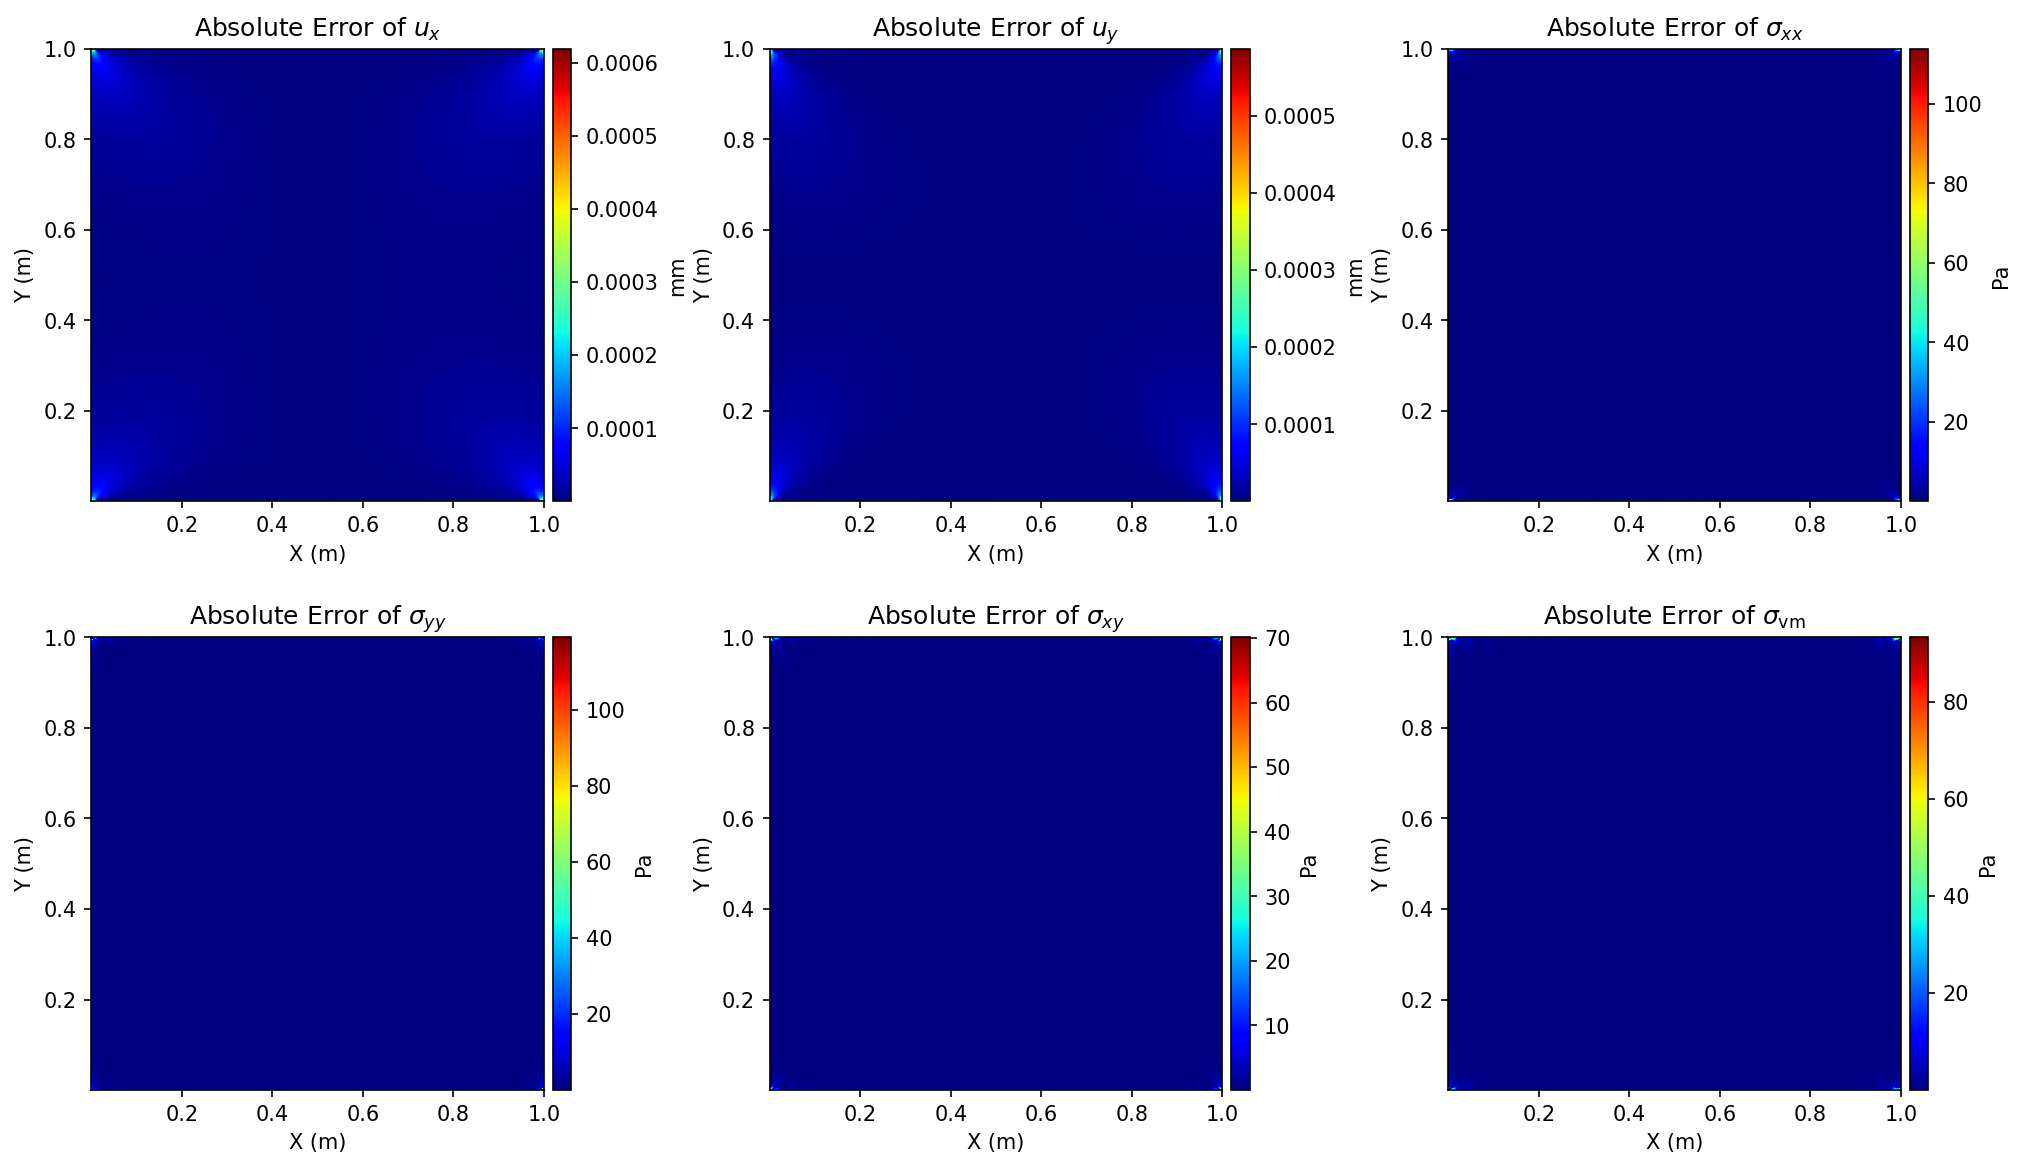

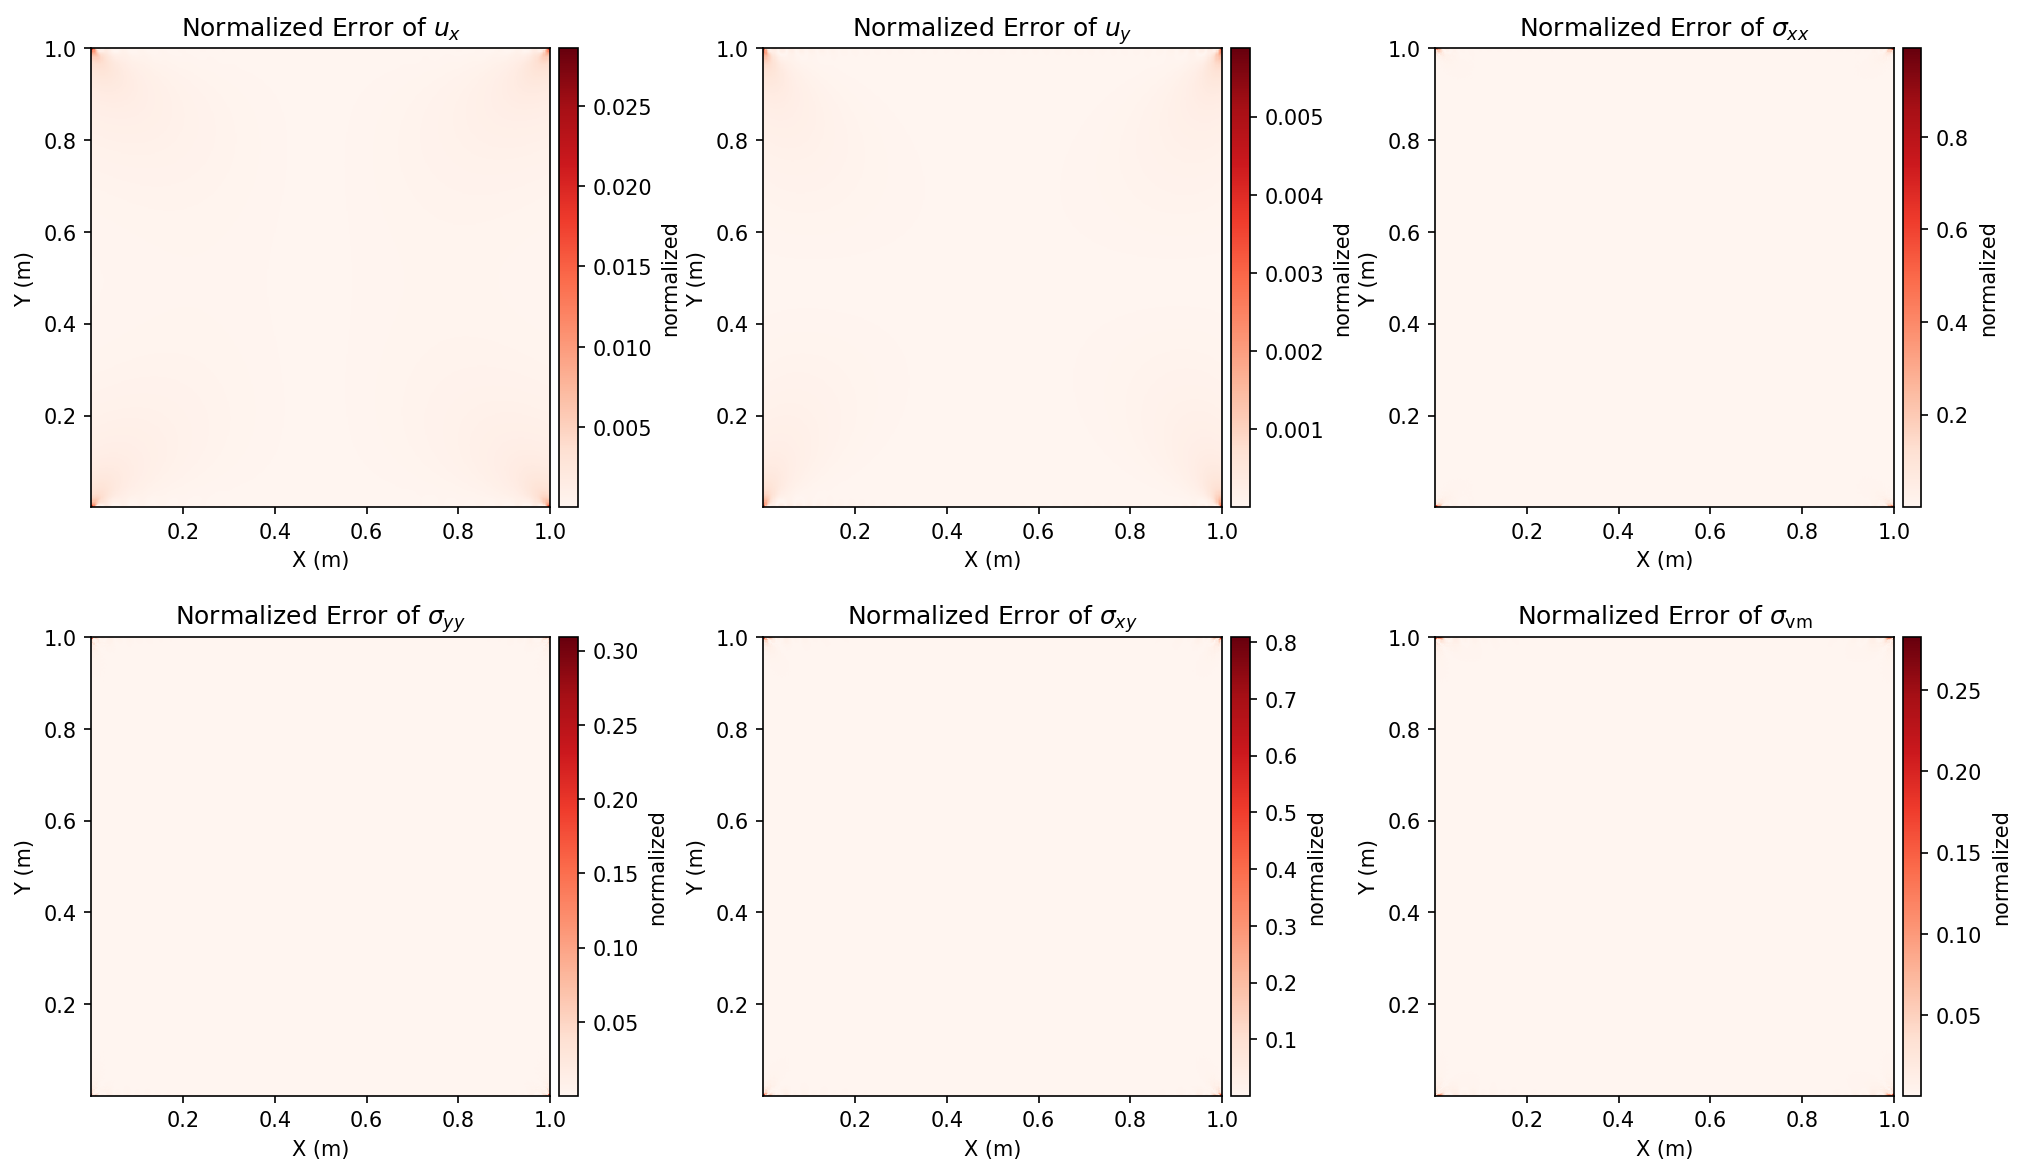

In [8]:
# ==========================================
# MFS 相对于 COMSOL 参考解的六物理量误差分析
# ==========================================
print("计算 MFS 相对于 COMSOL 参考解的六物理量 L2 误差、绝对误差云图和归一化误差云图...")


from pathlib import Path

COMSOL_REF_PATH = Path(r"C:\Users\magic\Desktop\KM-MFSNet\方板受压\方板受压comsol.txt")

def load_comsol_reference_table(txt_path=COMSOL_REF_PATH):
    """读取 COMSOL 电子表格 txt：X, Y, u, v, sx, sy, sxy, mises。"""
    txt_path = Path(txt_path)
    if not txt_path.exists():
        raise FileNotFoundError(f"找不到 COMSOL 参考解文件: {txt_path}")

    data = np.loadtxt(txt_path, comments="%")
    if data.ndim != 2 or data.shape[1] < 8:
        raise ValueError(f"COMSOL 文件至少需要 8 列，当前 shape={data.shape}")

    return {
        "points": data[:, 0:2].astype(np.float32),
        "x": data[:, 0],
        "y": data[:, 1],
        "ux": data[:, 2],
        "uy": data[:, 3],
        "sxx": data[:, 4],
        "syy": data[:, 5],
        "sxy": data[:, 6],
        "von_mises": data[:, 7],
        "raw": data,
    }

def regular_grid_from_points(points, values, decimals=12):
    points = np.asarray(points, dtype=float)
    values = np.asarray(values, dtype=float).reshape(-1)
    xr = np.round(points[:, 0], decimals)
    yr = np.round(points[:, 1], decimals)
    xs = np.unique(xr)
    ys = np.unique(yr)

    if xs.size * ys.size != values.size:
        raise ValueError(
            f"COMSOL 点不是规则网格: nx={xs.size}, ny={ys.size}, n={values.size}"
        )

    grid = np.full((ys.size, xs.size), np.nan, dtype=float)
    ix = np.searchsorted(xs, xr)
    iy = np.searchsorted(ys, yr)
    grid[iy, ix] = values
    if np.isnan(grid).any():
        raise ValueError("规则网格存在缺失点，请检查 COMSOL 导出数据。")
    return xs, ys, grid

def _add_equal_height_colorbar(fig, ax, im, label):
    from mpl_toolkits.axes_grid1 import make_axes_locatable
    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="4%", pad=0.06)
    cbar = fig.colorbar(im, cax=cax)
    cbar.set_label(label)
    return cbar

def relative_l2_error(pred, ref):
    pred = np.asarray(pred).reshape(-1)
    ref = np.asarray(ref).reshape(-1)
    return float(np.linalg.norm(pred - ref, 2) / max(np.linalg.norm(ref, 2), 1e-15))

def normalized_abs_error(pred, ref):
    pred = np.asarray(pred).reshape(-1)
    ref = np.asarray(ref).reshape(-1)
    return np.abs(pred - ref) / max(np.max(np.abs(ref)), 1e-15)

FIELD_ORDER = ["ux", "uy", "sxx", "syy", "sxy", "von_mises"]
FIELD_LABELS = {
    "ux": r"$u_x$",
    "uy": r"$u_y$",
    "sxx": r"$\sigma_{xx}$",
    "syy": r"$\sigma_{yy}$",
    "sxy": r"$\sigma_{xy}$",
    "von_mises": r"$\sigma_{\mathrm{vm}}$",
}
ABS_UNITS = {
    "ux": "mm",
    "uy": "mm",
    "sxx": "Pa",
    "syy": "Pa",
    "sxy": "Pa",
    "von_mises": "Pa",
}
ABS_SCALE = {
    "ux": 1e3,
    "uy": 1e3,
    "sxx": 1.0,
    "syy": 1.0,
    "sxy": 1.0,
    "von_mises": 1.0,
}

def build_six_field_error_data(pred, ref):
    metrics = {}
    absolute_errors_for_plot = {}
    normalized_errors = {}

    for key in FIELD_ORDER:
        pred_values = np.asarray(pred[key]).reshape(-1)
        ref_values = np.asarray(ref[key]).reshape(-1)
        abs_err = np.abs(pred_values - ref_values)
        norm_err = normalized_abs_error(pred_values, ref_values)

        metrics[f"L2_{key}"] = relative_l2_error(pred_values, ref_values)
        metrics[f"Max_abs_error_{key}"] = float(np.max(abs_err))
        metrics[f"Max_normalized_error_{key}"] = float(np.max(norm_err))

        absolute_errors_for_plot[key] = abs_err * ABS_SCALE[key]
        normalized_errors[key] = norm_err

    return metrics, absolute_errors_for_plot, normalized_errors

def print_six_field_error_table(method_name, metrics):
    print("-" * 92)
    print(f"{method_name} vs COMSOL six-field errors")
    print("-" * 92)
    print(f"{'Field':>12} {'Relative L2':>16} {'Max abs error':>18} {'Max norm error':>18}")
    print("-" * 92)
    for key in FIELD_ORDER:
        print(
            f"{key:>12} "
            f"{metrics[f'L2_{key}']:16.4e} "
            f"{metrics[f'Max_abs_error_{key}']:18.4e} "
            f"{metrics[f'Max_normalized_error_{key}']:18.4e}"
        )
    print("-" * 92)

    try:
        import pandas as pd
        table = pd.DataFrame([
            {
                "field": key,
                "relative_L2": metrics[f"L2_{key}"],
                "max_abs_error": metrics[f"Max_abs_error_{key}"],
                "max_normalized_error": metrics[f"Max_normalized_error_{key}"],
            }
            for key in FIELD_ORDER
        ])
        display(table)
        return table
    except Exception:
        return None

def plot_six_field_error_clouds(points, error_fields, title_prefix, colorbar_label, cmap, save_path):
    fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.0), dpi=150)
    for ax, key in zip(axes.ravel(), FIELD_ORDER):
        xs, ys, grid_values = regular_grid_from_points(points, error_fields[key])
        im = ax.pcolormesh(xs, ys, grid_values, shading="auto", cmap=cmap)
        ax.set_aspect("equal", adjustable="box")
        ax.set_title(f"{title_prefix} {FIELD_LABELS[key]}")
        ax.set_xlabel("X (m)")
        ax.set_ylabel("Y (m)")
        label = ABS_UNITS[key] if colorbar_label == "absolute" else "normalized"
        _add_equal_height_colorbar(fig, ax, im, label)

    fig.tight_layout()
    save_path = Path(save_path)
    save_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    print(f"误差云图已保存: {save_path}")
    return fig


def predict_mfs_fields_for_comsol(solution, pts, batch_size=20000):
    """在 COMSOL 坐标点上预测 MFS 的六物理量。"""
    fields = predict_mfs_physical_fields(solution, pts, batch_size=batch_size)
    return {
        "ux": fields["ux_real"],
        "uy": fields["uy_real"],
        "sxx": fields["sig_xx_real"],
        "syy": fields["sig_yy_real"],
        "sxy": fields["sig_xy_real"],
        "von_mises": fields["von_mises_real"],
    }

if "mfs_solution" not in globals():
    raise RuntimeError("请先运行 MFS 求解单元，确保变量 mfs_solution 已经存在。")
if "predict_mfs_physical_fields" not in globals():
    raise RuntimeError("请先运行包含 predict_mfs_physical_fields 的 MFS 后处理单元。")

mfs_comsol_ref = load_comsol_reference_table(COMSOL_REF_PATH)
mfs_comsol_pred = predict_mfs_fields_for_comsol(
    mfs_solution,
    mfs_comsol_ref["points"],
    batch_size=MFS_PRED_BATCH_SIZE if "MFS_PRED_BATCH_SIZE" in globals() else 20000,
)

mfs_error_metrics, mfs_abs_errors, mfs_normalized_errors = build_six_field_error_data(
    mfs_comsol_pred,
    mfs_comsol_ref,
)
mfs_error_table = print_six_field_error_table("MFS", mfs_error_metrics)

MFS_COMSOL_ERROR_OUT_DIR = Path("mfs_comsol_error_clouds")
fig_mfs_abs_error = plot_six_field_error_clouds(
    mfs_comsol_ref["points"],
    mfs_abs_errors,
    title_prefix="Absolute Error of",
    colorbar_label="absolute",
    cmap="jet",
    save_path=MFS_COMSOL_ERROR_OUT_DIR / "mfs_comsol_absolute_error_6_fields.png",
)
fig_mfs_norm_error = plot_six_field_error_clouds(
    mfs_comsol_ref["points"],
    mfs_normalized_errors,
    title_prefix="Normalized Error of",
    colorbar_label="normalized",
    cmap="Reds",
    save_path=MFS_COMSOL_ERROR_OUT_DIR / "mfs_comsol_normalized_error_6_fields.png",
)

plt.show()
